# Lab 15.2: The Logit Lens and a Fitted Lens on GPT-2 Small

Run every cell in order (Run All). Nothing needs to be edited. The notebook reads GPT-2 small at every layer in two ways:

1. the **logit lens**: apply the model's own final layer norm and unembedding to an intermediate residual stream vector;
2. an **affine lens**: first map each layer's vector with an affine translator fitted by least squares to predict the final-layer vector, then decode. This is a simplified, cheap relative of the tuned lens of Belrose et al. (2023), which trains its translators to minimize the KL divergence to the model's output instead.

Checkpoints are in the README.

In [1]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, torch
from transformer_lens import HookedTransformer
torch.manual_seed(0)
t0 = time.time()
model = HookedTransformer.from_pretrained("gpt2", device="cpu")  # GPT-2 small, 124M parameters
model.eval()
print("layers:", model.cfg.n_layers, "| width:", model.cfg.d_model, "| vocabulary:", model.cfg.d_vocab)

Loaded pretrained model gpt2 into HookedTransformer
layers: 12 | width: 768 | vocabulary: 50257


In [2]:
def lens_table(prompt, k=3):
    """Top-k logit-lens guesses for the next token at the last position, layer by layer."""
    toks = model.to_tokens(prompt)
    with torch.no_grad():
        logits, cache = model.run_with_cache(toks)
    final_top = int(logits[0, -1].argmax())
    rows = []
    for l in range(model.cfg.n_layers + 1):
        r = cache[f"blocks.{l}.hook_resid_pre"] if l < model.cfg.n_layers else cache[f"blocks.{l-1}.hook_resid_post"]
        with torch.no_grad():
            p = model.unembed(model.ln_final(r))[0, -1].softmax(-1)
        top = p.topk(k)
        rows.append({"layer": l,
                     **{f"guess {i+1}": f"{model.to_string(int(t))!r} {float(v):.2f}" for i, (t, v) in enumerate(zip(top.indices, top.values))},
                     "rank of final answer": int((p > p[final_top]).sum())})
    print(f"Prompt: {prompt!r}  ->  final answer {model.to_string(final_top)!r}")
    return pd.DataFrame(rows).set_index("layer")

lens_table("To reset your password, click the link we sent to your")

Prompt: 'To reset your password, click the link we sent to your'  ->  final answer ' email'


,guess 1,guess 2,guess 3,rank of final answer
layer,,,,
0,' your' 0.83,'your' 0.16,' mathemat' 0.01,18053
1,' own' 1.00,' favorite' 0.00,' body' 0.00,367
2,' own' 1.00,' favorite' 0.00,' personal' 0.00,123
3,' own' 1.00,' personal' 0.00,' browser' 0.00,20
4,' own' 1.00,' favorite' 0.00,' browser' 0.00,7
5,' own' 1.00,' respective' 0.00,' browser' 0.00,5
6,' own' 0.94,' email' 0.02,' respective' 0.01,1
7,' email' 0.58,' own' 0.27,' inbox' 0.03,0
8,' email' 0.35,' mailbox' 0.34,' inbox' 0.23,0


**Checkpoint 1.** Layer 0 decodes to odd tokens (the embedding is not meant to be read by the unembedding). From layer 1 to layer 6 the top guess is `' own'`; `' email'` becomes the top guess at layer 7 and stays there. Read the column "rank of final answer": when does `' email'` enter the top 10?

In [3]:
for p in ["The Eiffel Tower is located in the city of",
          "The capital of Japan is the city of",
          "I would like a refund because the package arrived"]:
    display(lens_table(p))

Prompt: 'The Eiffel Tower is located in the city of'  ->  final answer ' London'


,guess 1,guess 2,guess 3,rank of final answer
layer,,,,
0,' destro' 0.60,' mathemat' 0.26,' challeng' 0.12,21746
1,' the' 0.73,' course' 0.05,' a' 0.03,706
2,' the' 0.83,' course' 0.05,' a' 0.02,443
3,' the' 0.68,' course' 0.17,' a' 0.02,86
4,' the' 0.63,' course' 0.08,' a' 0.01,167
5,' the' 0.30,' La' 0.07,' course' 0.04,313
6,' England' 0.08,' La' 0.05,' the' 0.04,56
7,' South' 0.05,' Georgia' 0.05,' East' 0.05,44
8,' Ing' 0.22,' San' 0.06,' Chicago' 0.04,17


Prompt: 'The capital of Japan is the city of'  ->  final answer ' Tokyo'


,guess 1,guess 2,guess 3,rank of final answer
layer,,,,
0,' destro' 0.65,' mathemat' 0.26,' challeng' 0.08,42622
1,' the' 0.70,' course' 0.06,' a' 0.03,1783
2,' the' 0.80,' course' 0.06,' a' 0.02,1104
3,' the' 0.66,' course' 0.20,' a' 0.02,982
4,' the' 0.71,' course' 0.12,' a' 0.01,949
5,' the' 0.66,' its' 0.05,' course' 0.02,932
6,' the' 0.39,' its' 0.06,' course' 0.02,1413
7,' the' 0.21,' Ar' 0.05,' Giants' 0.04,262
8,' the' 0.09,' Ar' 0.05,' honor' 0.05,345


Prompt: 'I would like a refund because the package arrived'  ->  final answer ' in'


,guess 1,guess 2,guess 3,rank of final answer
layer,,,,
0,' arrived' 1.00,' mathemat' 0.00,' arrive' 0.00,30127
1,' arrived' 0.36,' arrive' 0.14,' arrives' 0.10,5
2,' arrived' 0.23,' upon' 0.10,' at' 0.09,4
3,' shipping' 0.24,' here' 0.16,' upon' 0.08,6
4,' here' 0.43,' shipping' 0.09,' at' 0.08,4
5,' here' 0.33,' at' 0.30,' in' 0.03,2
6,' here' 0.18,' at' 0.17,' upon' 0.06,3
7,' at' 0.17,' here' 0.06,' unexpectedly' 0.06,6
8,' at' 0.15,' properly' 0.11,' unexpectedly' 0.11,5


**Checkpoint 2.** For the Eiffel Tower prompt GPT-2 small ends on `' London'`, with `' Paris'` a close second: the lens shows where the wrong answer is built (layers 9 to 12). For Japan, `' Tokyo'` reaches 0.86 at layer 10 and falls to about 0.10 at the output: the last layers spread probability. For the refund prompt, the final answer `' in'` appears only at the very last layer.

## Every position at every layer

The next cell shows the top logit-lens guess for every position of one prompt (rows = layers, columns = input tokens).

In [4]:
prompt = "To reset your password, click the link we sent to your"
toks = model.to_tokens(prompt)
with torch.no_grad():
    _, cache = model.run_with_cache(toks)
grid = {}
for l in range(13):
    r = cache[f"blocks.{l}.hook_resid_pre"] if l < 12 else cache["blocks.11.hook_resid_post"]
    with torch.no_grad():
        top = model.unembed(model.ln_final(r))[0].argmax(-1)
    grid[l] = [model.to_string(int(t)) for t in top]
pd.DataFrame(grid, index=[repr(s) for s in model.to_str_tokens(prompt)]).T.iloc[::-1]

,'<|endoftext|>','To',' reset',' your',' password',"','",' click',' the',' link',' we',' sent',' to',' your'
12,\n,be,the,password,",",please,the,"""",below,sent,you,you,email
11,",",view,your,password,",",click,on,button,below,posted,you,your,email
10,",",ilet,your,password,password,click,Settings,button,below,posted,him,your,email
9,",",ilet,your,password,password,please,Cancel,button,below,'ve,email,your,email
8,",",ilet,reset,own,password,please,Cancel,button,below,'ve,email,your,email
7,",",ilet,reset,own,password,please,lish,button,link,'ve,email,the,email
6,",",ilet,reset,own,password,please,lish,button,link,'ve,email,the,own
5,",",get,reset,own,password,please,lish,same,link,'ve,email,the,own
4,",",take,reset,own,password,please,lish,same,link,'ve,send,get,own
3,",",get,reset,own,password,please,click,same,link,'ve,email,get,own


## Fitting an affine lens and comparing it with the logit lens

GPT-2 has no public validation set, so we sample text from GPT-2 itself (192 sequences of 64 tokens, fixed seed). The first 144 sequences fit one affine translator per layer by ridge-regularized least squares; the last 48 evaluate. We measure the KL divergence (in bits) from the model's final output distribution to each lens, and how often each lens has the same top token as the model. This cell takes a few minutes on a laptop CPU.

In [5]:
torch.manual_seed(0)
bos = torch.full((32, 1), model.tokenizer.bos_token_id)
with torch.no_grad():
    S = torch.cat([model.generate(bos, max_new_tokens=64, do_sample=True, temperature=1.0, verbose=False) for _ in range(6)])
names = [f"blocks.{l}.hook_resid_pre" for l in range(12)] + ["blocks.11.hook_resid_post"]
acts = {n: [] for n in names}
with torch.no_grad():
    for i in range(0, len(S), 32):
        _, c = model.run_with_cache(S[i:i+32], names_filter=lambda n: n in names)
        for n in names:
            acts[n].append(c[n][:, 1:].reshape(-1, model.cfg.d_model))
acts = {n: torch.cat(v) for n, v in acts.items()}
N = acts[names[0]].shape[0]; ntr = int(N * 0.75)
fin = acts[names[-1]]
decode = lambda h: model.unembed(model.ln_final(h.unsqueeze(0)))[0]
idx = torch.arange(ntr, N)[::3]
rows = []
with torch.no_grad():
    P = decode(fin[idx]).log_softmax(-1)
    for l in range(13):
        h = acts[names[l]]
        X = torch.cat([h, torch.ones(N, 1)], 1)
        W = torch.linalg.solve(X[:ntr].T @ X[:ntr] + 0.1 * torch.eye(X.shape[1]), X[:ntr].T @ fin[:ntr])
        row = {"layer": l}
        for key, Q in (("logit lens", decode(h[idx]).log_softmax(-1)), ("affine lens", decode(X[idx] @ W).log_softmax(-1))):
            row[f"KL bits, {key}"] = float((P.exp() * (P - Q)).sum(-1).mean()) / np.log(2)
            row[f"same top token, {key}"] = float((Q.argmax(-1) == P.argmax(-1)).float().mean())
        rows.append(row)
lens = pd.DataFrame(rows).set_index("layer").round(3)
lens.to_csv("lens_results.csv")
print(f"fit tokens: {ntr}, evaluation tokens: {len(idx)}, minutes so far: {(time.time()-t0)/60:.1f}")
lens

fit tokens: 9216, evaluation tokens: 1024, minutes so far: 2.0


,"KL bits, logit lens","same top token, logit lens","KL bits, affine lens","same top token, affine lens"
layer,,,,
0,70.219,0.006,4.611,0.192
1,9.298,0.113,3.948,0.220
2,8.244,0.113,3.646,0.252
3,7.561,0.125,3.434,0.271
4,7.058,0.148,3.107,0.286
5,6.651,0.151,2.895,0.289
6,6.237,0.171,2.576,0.315
7,5.731,0.199,2.193,0.360
8,5.217,0.256,1.735,0.410


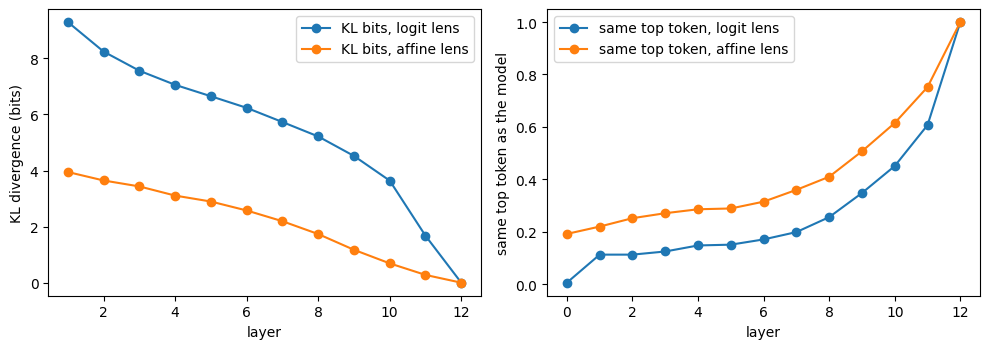

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
lens.iloc[1:, [0, 2]].plot(ax=ax[0], marker="o"); ax[0].set_ylabel("KL divergence (bits)")
lens.iloc[:, [1, 3]].plot(ax=ax[1], marker="o"); ax[1].set_ylabel("same top token as the model")
plt.tight_layout(); plt.show()

**Checkpoint 3.** At every layer from 1 to 11 the affine lens is closer to the model's output than the logit lens (lower KL, higher top-token agreement). Both reach 0 KL at layer 12 by construction. Answer the README questions before you change anything. If you want to explore, copy the notebook and try your own prompts with `lens_table`.